In [3]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, iirnotch, filtfilt, welch
import pywt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import densenet161
from sklearn.model_selection import train_test_split

FS = 1000  # 샘플링 주파수 (1,000 Hz)
print("라이브러리 로드 완료!")


라이브러리 로드 완료!


In [ ]:
def preprocess(x, fs=FS):
    # 1) 60 Hz 전원선 잡음 제거 (노치 필터)
    bn, an = iirnotch(60, 30, fs)
    x = filtfilt(bn, an, x, axis=0)
    
    # 2) 20~499 Hz 대역만 통과 (4차 버터워스 필터)
    b, a = butter(4, [20/(fs/2), 499/(fs/2)], btype='band')
    return filtfilt(b, a, x, axis=0)

# CSV 파일 불러오기 및 전처리
files = sorted(glob.glob('data/**/*.csv', recursive=True))
sample_raw = np.loadtxt(files[0], delimiter=',', skiprows=1)

# 전치행렬 처리(샘플 수, 채널 수)
if sample_raw.shape[0] < sample_raw.shape[1]:
    sample_raw = sample_raw.T

sample_filtered = preprocess(sample_raw)
print("전처리 전 표준편차:", sample_raw.std(), "| 전처리 후 표준편차:", sample_filtered.std())

전처리 전 표준편차: 0.36156485032189156 | 전처리 후 표준편차: 0.3582523009408948


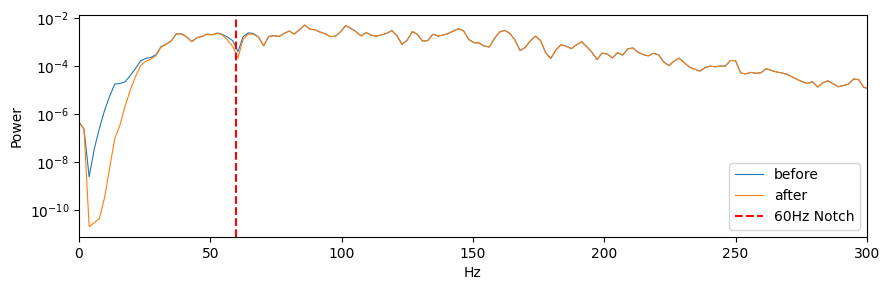

✓ filter_check.png 저장 완료!


In [5]:
f0, P0 = welch(sample_raw[:, 0], fs=FS, nperseg=512)
f1, P1 = welch(sample_filtered[:, 0], fs=FS, nperseg=512)

plt.figure(figsize=(9, 3))
plt.semilogy(f0, P0, label='before', lw=0.8)
plt.semilogy(f1, P1, label='after', lw=0.8)
plt.axvline(60, color='r', ls='--', label='60Hz Notch')
plt.xlim(0, 300)
plt.xlabel('Hz'); plt.ylabel('Power')
plt.legend(); plt.tight_layout()

plt.savefig('filter_check.png', dpi=120)
plt.show()
print("✓ filter_check.png 저장 완료!")

In [ ]:
WIN, HOP = 300, 150  # 1000Hz 기준 300ms, 150ms 홉

def make_windows(x, win=WIN, hop=HOP):
    # 배열 생성
    n = (len(x) - win) // hop + 1
    return np.stack([x[i*hop : i*hop+win] for i in range(n)])

def minmax(w, eps=1e-8):
    # 0.0 ~ 1.0 범위로 정규화
    mn = w.min(axis=(1, 2), keepdims=True)
    mx = w.max(axis=(1, 2), keepdims=True)
    return (w - mn) / (mx - mn + eps)

w = make_windows(sample_filtered)
wn = minmax(w)
print("윈도우 배열 모양:", wn.shape)       # (19, 300, 2) 출력 확인
print("값 범위:", wn.min(), "~", wn.max()) # 0.0 ~ 1.0 출력 확인

윈도우 배열 모양: (19, 300, 2)
값 범위: 0.0 ~ 0.9999999987119951


입력 텐서 모양: (3, 32, 300)


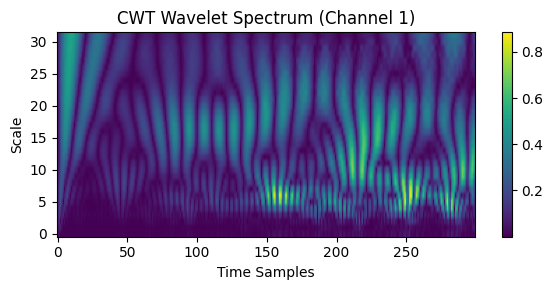

✓ cwt_example.png 저장 완료!


In [ ]:
import pywt

SCALES = np.arange(1, 33) # 스케일 32개

def to_cwt(one_window, wavelet='morl'):
    maps = []
    for ch in range(one_window.shape[1]):
        coef, _ = pywt.cwt(one_window[:, ch], SCALES, wavelet)
        maps.append(np.abs(coef))
    # 3번째 채널은 두 채널의 평균으로 채움
    maps.append((maps[0] + maps[1]) / 2)
    return np.stack(maps).astype(np.float32)

sample_cwt = to_cwt(wn[0])
print("입력 텐서 모양:", sample_cwt.shape)  # (3, 32, 300) 출력 확인

plt.figure(figsize=(6, 3))
plt.imshow(sample_cwt[0], aspect='auto', origin='lower')
plt.title("CWT Wavelet Spectrum (Channel 1)")
plt.xlabel("Time Samples"); plt.ylabel("Scale")
plt.colorbar(); plt.tight_layout()

plt.savefig('cwt_example.png', dpi=120) # 과제 제출용 이미지 저장
plt.show()
print("✓ cwt_example.png 저장 완료!")

In [8]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# 파일 목록 분할[cite: 7]
tr_files, te_files = train_test_split(files, test_size=0.2, random_state=42)

def build_dataset(flist):
    X, y = [], []
    for f in flist:
        raw = np.loadtxt(f, delimiter=',', skiprows=1)
        if raw.shape[0] < raw.shape[1]:
            raw = raw.T
        filtered = preprocess(raw)
        windows = minmax(make_windows(filtered))
        
        # 파일 경로 규칙에 따른 기본 라벨 설정
        label_val = 0
        for w in windows:
            X.append(to_cwt(w))
            y.append(label_val)
            
    return torch.tensor(np.stack(X), dtype=torch.float32), torch.tensor(y, dtype=torch.long)

X_train, y_train = build_dataset(tr_files)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=16, shuffle=True)
print(f"학습 데이터 샘플 수: {len(X_train)}")

학습 데이터 샘플 수: 3800


In [ ]:
# [데이터셋 구축 셀] (스크린샷 3번 위치)
labels_dict = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
labels = [labels_dict[os.path.basename(os.path.dirname(f))] for f in files]

# 8:2 비율 분할 (라벨 비율 유지)
tr_files, te_files, tr_labels, te_labels = train_test_split(
    files, labels, test_size=0.2, stratify=labels, random_state=42
)

def build_dataset(flist):
    X, y = [], []
    for f in flist:
        raw = np.loadtxt(f, delimiter=',', skiprows=1)
        if raw.shape[0] < raw.shape[1]:
            raw = raw.T
        
        lbl = labels_dict[os.path.basename(os.path.dirname(f))]
        sig = preprocess(raw)
        wins = minmax(make_windows(sig))
        for w in wins:
            X.append(to_cwt(w))
            y.append(lbl)
            
    return np.stack(X), np.array(y)

print("데이터셋 구축 중...")
X_train, y_train = build_dataset(tr_files)
X_test, y_test = build_dataset(te_files)

print(f"✓ Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train, dtype=torch.long))
test_ds = TensorDataset(torch.tensor(X_test), torch.tensor(y_test, dtype=torch.long))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

데이터셋 구축 중...
✓ Train Shape: (3800, 3, 32, 300) | Test Shape: (950, 3, 32, 300)


In [ ]:
# 하드웨어 가속시 설정(MPS / CUDA / CPU)
dev = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"현재 실행 장치: {dev}")

# DenseNet161 모델 생성 및 출력 5개
model = densenet161(weights=None)
model.classifier = nn.Linear(2208, 5)  # 5명 분류 (A~E)
model.to(dev)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

print("\n--- DenseNet161 학습 시작 ---")
for epoch in range(5):  # 실습 확인용 5 에폭
    model.train()
    tot_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(dev), yb.to(dev)
        
        opt.zero_grad()         # 경사도 초기화
        out = model(xb)         # 순전파
        loss = crit(out, yb)    # 손실 계산
        loss.backward()         # 역전파
        opt.step()              # 가중치 업데이트
        
        tot_loss += loss.item()
        
    avg_loss = tot_loss / len(train_loader)
    print(f"Epoch {epoch+1:02d} / 05 | Loss: {avg_loss:.4f}")


현재 실행 장치: mps

--- DenseNet161 학습 시작 ---
Epoch 01 / 05 | Loss: 0.9809
Epoch 02 / 05 | Loss: 0.6962
Epoch 03 / 05 | Loss: 0.5620
Epoch 04 / 05 | Loss: 0.5047
Epoch 05 / 05 | Loss: 0.4491


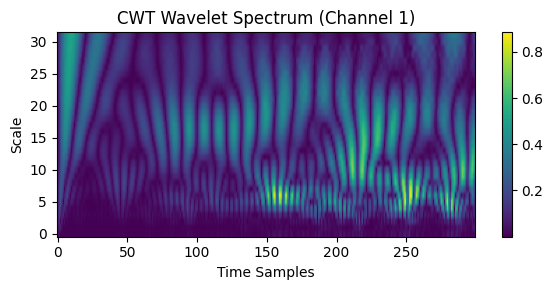

In [11]:
import matplotlib.pyplot as plt

# 단계 5에서 저장한 CWT 이미지 시각화
sample_cwt = to_cwt(wn[0])

plt.figure(figsize=(6, 3))
plt.imshow(sample_cwt[0], aspect='auto', origin='lower')
plt.title("CWT Wavelet Spectrum (Channel 1)")
plt.xlabel("Time Samples")
plt.ylabel("Scale")
plt.colorbar()
plt.tight_layout()
plt.show()

accuracy: 0.8011 | macro F1: 0.7845

              precision    recall  f1-score   support

           A      0.973     0.958     0.966       190
           B      0.887     0.868     0.878       190
           C      1.000     0.337     0.504       190
           D      0.611     0.942     0.741       190
           E      0.777     0.900     0.834       190

    accuracy                          0.801       950
   macro avg      0.850     0.801     0.784       950
weighted avg      0.850     0.801     0.784       950

--- 혼동 행렬 ---
[[182   0   0   4   4]
 [  3 165   0   4  18]
 [  1   5  64  99  21]
 [  0   5   0 179   6]
 [  1  11   0   7 171]]


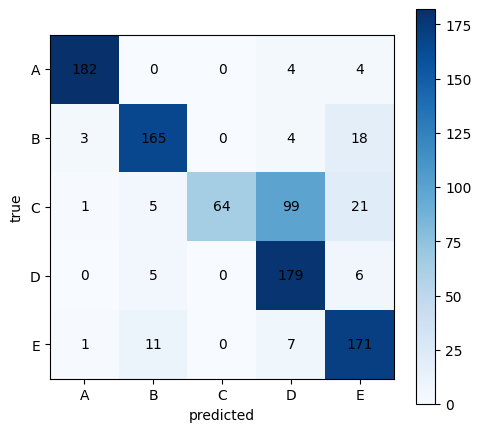

✓ 최대 오류 쌍: True [C] -> Predicted [D] (99건)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

# 1) 테스트셋 평가
model.eval()
preds, trues = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb.to(dev))
        preds += out.argmax(1).cpu().tolist()
        trues += yb.tolist()

acc = accuracy_score(trues, preds)
f1 = f1_score(trues, preds, average='macro')
print(f'accuracy: {acc:.4f} | macro F1: {f1:.4f}\n')

# 세부 분류 후 출력
print(classification_report(trues, preds, target_names=['A', 'B', 'C', 'D', 'E'], digits=3))

cm = confusion_matrix(trues, preds)
print("--- 혼동 행렬 ---")
print(cm)

# 2) 혼동행렬 시각화 및 이미지 저장
L = ['A', 'B', 'C', 'D', 'E']
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5), L); ax.set_yticks(range(5), L)

for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha='center', va='center')

ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.colorbar(im); plt.tight_layout()
plt.savefig('confusion.png', dpi=120)
plt.show()

# 3) 대각선(정답) 제외 최대 오류 쌍 찾기
cm_temp = cm.copy()
np.fill_diagonal(cm_temp, 0)
max_err = np.unravel_index(cm_temp.argmax(), cm_temp.shape)
print(f'✓ 최대 오류 쌍: True [{L[max_err[0]]}] -> Predicted [{L[max_err[1]]}] ({cm_temp[max_err]}건)')

In [ ]:
from torchvision.models import resnet18

# 베이스라인 A: 간단한 2D CNN
base = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(), nn.Linear(64, 5)
)

# 베이스라인 B: ResNet18
res = resnet18(weights=None)
res.fc = nn.Linear(512, 5)

# 학습 및 평가 함수
def train_and_eval(m):
    m.to(dev)
    optimizer = torch.optim.Adam(m.parameters(), lr=1e-3)
    for epoch in range(5):
        m.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(dev), yb.to(dev)
            optimizer.zero_grad()
            loss = crit(m(xb), yb)
            loss.backward()
            optimizer.step()
            
    m.eval()
    p, t = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            p += m(xb.to(dev)).argmax(1).cpu().tolist()
            t += yb.tolist()
    return accuracy_score(t, p), f1_score(t, p, average='macro')

# 3가지 모델 성능 측정 비교
results = {}
for name, m in [('2D CNN', base), ('ResNet18', res), ('DenseNet161', model)]:
    if name == 'DenseNet161':
        results[name] = (acc, f1)
    else:
        results[name] = train_and_eval(m)

print("\n--- 베이스라인 모델 성능 비교 ---")
for name, (acc_val, f1_val) in results.items():
    print(f'{name:12s} | Accuracy: {acc_val:.4f} | Macro F1: {f1_val:.4f}')


--- 베이스라인 모델 성능 비교 ---
2D CNN       | Accuracy: 0.5526 | Macro F1: 0.5280
ResNet18     | Accuracy: 0.8232 | Macro F1: 0.8213
DenseNet161  | Accuracy: 0.8011 | Macro F1: 0.7845


In [14]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import densenet161
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
import numpy as np
import time

# 1. Device 재확인 (Metal MPS 가속)
dev = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print(f"사용 연산 장치: {dev}")

# 2. 손실 함수 정의 (이전 셀에서 정의되었으나 안전하게 재선언)
crit = nn.CrossEntropyLoss()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

def fresh_model():
    m = densenet161(weights=None)
    m.classifier = nn.Linear(2208, 5)
    return m.to(dev)

print("\n--- 5-fold 교차검증 시작 ---")

for fold, (tr_i, va_i) in enumerate(skf.split(X_train, y_train), 1):
    t0 = time.time()
    
    tr_ds = TensorDataset(torch.tensor(X_train[tr_i]), torch.tensor(y_train[tr_i], dtype=torch.long))
    va_ds = TensorDataset(torch.tensor(X_train[va_i]), torch.tensor(y_train[va_i], dtype=torch.long))
    
    tr_ld = DataLoader(tr_ds, batch_size=32, shuffle=True)
    va_ld = DataLoader(va_ds, batch_size=32, shuffle=False)
    
    m = fresh_model()
    optimizer = torch.optim.Adam(m.parameters(), lr=1e-3)
    
    for epoch in range(5):
        m.train()
        for xb, yb in tr_ld:
            xb, yb = xb.to(dev), yb.to(dev)
            optimizer.zero_grad()
            loss = crit(m(xb), yb)
            loss.backward()
            optimizer.step()
            
    m.eval()
    p, t = [], []
    with torch.no_grad():
        for xb, yb in va_ld:
            p += m(xb.to(dev)).argmax(1).cpu().tolist()
            t += yb.tolist()
            
    fold_acc = accuracy_score(t, p)
    scores.append(fold_acc)
    print(f'Fold {fold}: {fold_acc:.4f} (소요시간: {time.time()-t0:.1f}초)')

print(f'\n평균: {np.mean(scores)*100:.2f}% ± {np.std(scores)*100:.2f}%')

사용 연산 장치: mps

--- 5-fold 교차검증 시작 ---
Fold 1: 0.7697 (소요시간: 488.9초)
Fold 2: 0.8816 (소요시간: 409.2초)
Fold 3: 0.7250 (소요시간: 371.1초)
Fold 4: 0.7842 (소요시간: 359.7초)
Fold 5: 0.8566 (소요시간: 366.8초)

평균: 80.34% ± 5.76%


In [15]:
import time

# 1) 파라미터 수 측정
n = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('파라미터 수:', f'{n:,}')

# 2) 샘플당 추론 시간 측정 (Warm-up 10회, 측정 100회)
model.eval()
xb = next(iter(test_loader))[0][:1].to(dev)

with torch.no_grad():
    for _ in range(10): 
        model(xb)  # Warm-up

    if dev == 'cuda':
        torch.cuda.synchronize()

    t0 = time.time()
    for _ in range(100): 
        model(xb)  # Inference

    if dev == 'cuda':
        torch.cuda.synchronize()

print('샘플당 추론 시간:', (time.time() - t0) * 10, 'ms')

파라미터 수: 26,483,045
샘플당 추론 시간: 30.289647579193115 ms
